# Port 22 DBSCAN/HDBSCAN Clustering

In [1]:
pip install polars pandas scikit-learn numpy matplotlib openai tqdm python-dotenv ollama jsonschema kneed umap-learn hdbscan


[notice] A new release of pip is available: 26.1.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Load & dataset

In [2]:
import polars as pl

df = pl.read_csv("results/sorted_enriched_port_22.csv")

df.describe()

statistic,id,expiration_id,src_ip,src_mac,src_oui,src_port,dst_ip,dst_mac,dst_oui,dst_port,protocol,ip_version,vlan_id,tunnel_id,bidirectional_first_seen_ms,bidirectional_last_seen_ms,bidirectional_duration_ms,bidirectional_packets,bidirectional_bytes,src2dst_first_seen_ms,src2dst_last_seen_ms,src2dst_duration_ms,src2dst_packets,src2dst_bytes,dst2src_first_seen_ms,dst2src_last_seen_ms,dst2src_duration_ms,dst2src_packets,dst2src_bytes,bidirectional_min_ps,bidirectional_mean_ps,bidirectional_stddev_ps,bidirectional_max_ps,src2dst_min_ps,src2dst_mean_ps,src2dst_stddev_ps,…,src2dst_urg_packets,src2dst_ack_packets,src2dst_psh_packets,src2dst_rst_packets,src2dst_fin_packets,dst2src_syn_packets,dst2src_cwr_packets,dst2src_ece_packets,dst2src_urg_packets,dst2src_ack_packets,dst2src_psh_packets,dst2src_rst_packets,dst2src_fin_packets,splt_direction,splt_ps,splt_piat_ms,application_name,application_category_name,application_is_guessed,application_confidence,requested_server_name,client_fingerprint,server_fingerprint,user_agent,content_type,auth_success,auth_attempts,ssh_versions,clients,servers,cipher_algs,mac_algs,compression_algs,kex_algs,host_key_algs,host_keys,ssh_record_count
str,f64,f64,str,str,str,f64,str,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,f64,f64,str,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,str,f64
"""count""",317665.0,317665.0,"""317665""","""317665""","""317665""",317665.0,"""317665""","""317665""","""317665""",317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,…,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,317665.0,"""317665""","""317665""","""317665""","""317665""","""317665""",317665.0,317665.0,"""215""","""50751""","""14698""","""158""","""0""","""56294""",56294.0,"""56294""","""56294""","""56294""","""56294""","""56294""","""56294""","""56294""","""56294""","""56294""",316302.0
"""null_count""",0.0,0.0,"""0""","""0""","""0""",0.0,"""0""","""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,…,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""","""0""","""0""","""0""","""0""",0.0,0.0,"""317450""","""266914""","""302967""","""317507""","""317665""","""261371""",261371.0,"""261371""","""261371""","""261371""","""261371""","""261371""","""261371""","""261371""","""261371""","""261371""",1363.0
"""mean""",28841.179595,0.0,null,null,null,49153.187248,null,null,null,138.115508,6.0,4.0,0.0,0.0,1.7574e12,1.7574e12,19504.877487,14.305237,5048.370242,1.7574e12,1.7574e12,1494.15919,7.256355,4352.29862,1.7533e12,1.7533e12,19330.82304,7.048882,696.071623,59.193742,78.687147,41.287121,237.87064,61.348348,82.185386,47.473824,…,0.0,6.000258,3.197554,0.249886,0.165747,3.743661,0.001574,0.001269,0.0,7.044862,1.554052,0.004023,0.203655,null,null,null,null,null,0.835515,1.833302,null,null,null,null,null,null,0.49984,null,null,null,null,null,null,null,null,null,0.164937
"""std""",32351.116842,0.0,null,null,null,7670.390369,null,null,null,2442.819504,0.0,0.0,0.0,0.0,1.9789e9,1.9789e9,19855.061639,270.758439,295834.479452,1.9789e9,1.9789e9,9212.553691,223.532537,291861.168358,8.4229e10,8.4229e10,19695.947911,58.414635,4925.871015,6.551552,46.70723,89.143087,393.180009,7.132685,52.587203,106.418369,…,0.0,223.537731,111.127392,0.458637,0.39436,2.495677,0.150876,0.047026,0.0,58.372812,9.819518,0.21664,0.650779,null,null,null,null,null,0.370715,1.845858,null,null,null,null,null,null,0.507865,null,null,null,null,null,null,null,null,null,0.37189
"""min""",0.0,0.0,"""1.117.26.65""","""bc:24:11:83:a7:6c""","""bc:24:11""",22.0,"""101.126.149.19""","""bc:24:11:8

In [3]:
port_freq = df["dst_port"].value_counts()
print(port_freq)

shape: (99, 2)
┌──────────┬───────┐
│ dst_port ┆ count │
│ ---      ┆ ---   │
│ i64      ┆ u32   │
╞══════════╪═══════╡
│ 54088    ┆ 63    │
│ 54130    ┆ 1     │
│ 49192    ┆ 63    │
│ 35179    ┆ 1     │
│ 47708    ┆ 1     │
│ …        ┆ …     │
│ 42967    ┆ 1     │
│ 16545    ┆ 1     │
│ 55908    ┆ 3     │
│ 47176    ┆ 1     │
│ 18474    ┆ 1     │
└──────────┴───────┘


Too much variance in ports, One hot encoding not worth it

In [4]:
import pandas as pd

if "application_confidence" in df.columns:
  df = df.with_columns(
    (pl.col("application_confidence") >= 4).cast(pl.Int8).alias("is_high_confidence")
  )
  df = df.drop("application_confidence")

if "tunnel_id" in df.columns:
  df = df.with_columns(
    pl.col("tunnel_id").cast(pl.Utf8)
  ).to_dummies(columns=["tunnel_id"])

columns_to_drop = [
  # Remove numeric identifiers
  'id', 'expiration_id',

  # Remove string identifiers
  'src_ip', 'dst_ip', 'src_mac', 'dst_mac', 'src_oui', 'dst_oui', 'src_port', 'dst_port',
  
  # Remove strings
  'application_name', 'application_category_name', 'client_fingerprint', 'server_fingerprint', 'requested_server_name', 
  'user_agent', 'content_type',

  # Remove features that may leak timestamp
  'bidirectional_first_seen_ms', 'bidirectional_last_seen_ms', 'src2dst_first_seen_ms', 'src2dst_last_seen_ms',
  'dst2src_first_seen_ms', 'dst2src_last_seen_ms','splt_direction', 'splt_ps', 'splt_piat_ms',

  # Remove added Zeek Feautures used to conduct DPI on the clusters after clustering is performed
  'auth_attempts', 'auth_success', 'clients', 'servers', 'ssh_versions','cipher_algs', 
  'mac_algs', 'kex_algs', 'host_key_algs', 'compression_algs',	'host_keys',	'ssh_record_count',
]

df = df.drop([col for col in columns_to_drop if col in df.columns])

nunique_df = df.select(pl.all().n_unique())
constant_cols = [
  col for col, val in zip(nunique_df.columns, nunique_df.row(0))
  if val <= 1
]
df = df.drop(constant_cols)

print(f"Dropped {len(columns_to_drop)} string/list columns and {len(constant_cols)} constant columns")
df.head()

Dropped 38 string/list columns and 7 constant columns


bidirectional_duration_ms,bidirectional_packets,bidirectional_bytes,src2dst_duration_ms,src2dst_packets,src2dst_bytes,dst2src_duration_ms,dst2src_packets,dst2src_bytes,bidirectional_min_ps,bidirectional_mean_ps,bidirectional_stddev_ps,bidirectional_max_ps,src2dst_min_ps,src2dst_mean_ps,src2dst_stddev_ps,src2dst_max_ps,dst2src_min_ps,dst2src_mean_ps,dst2src_stddev_ps,dst2src_max_ps,bidirectional_min_piat_ms,bidirectional_mean_piat_ms,bidirectional_stddev_piat_ms,bidirectional_max_piat_ms,src2dst_min_piat_ms,src2dst_mean_piat_ms,src2dst_stddev_piat_ms,src2dst_max_piat_ms,dst2src_min_piat_ms,dst2src_mean_piat_ms,dst2src_stddev_piat_ms,dst2src_max_piat_ms,bidirectional_syn_packets,bidirectional_cwr_packets,bidirectional_ece_packets,bidirectional_ack_packets,bidirectional_psh_packets,bidirectional_rst_packets,bidirectional_fin_packets,src2dst_syn_packets,src2dst_cwr_packets,src2dst_ece_packets,src2dst_ack_packets,src2dst_psh_packets,src2dst_rst_packets,src2dst_fin_packets,dst2src_syn_packets,dst2src_cwr_packets,dst2src_ece_packets,dst2src_ack_packets,dst2src_psh_packets,dst2src_rst_packets,dst2src_fin_packets,application_is_guessed,is_high_confidence
i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i8
1008,14,1548,1008,7,846,800,7,702,66,110.571429,37.222231,162,66,120.857143,40.114123,162,66,100.285714,33.851215,146,0,77.538462,90.145822,207,0,168.0,86.833173,253,1,133.333333,91.090431,218,0,0,0,14,9,0,2,0,0,0,7,5,0,1,0,0,0,7,4,0,1,1,0
1785,29,4653,1785,15,2498,1598,14,2155,66,160.448276,210.225319,1042,66,166.533333,244.738305,1042,66,153.928571,174.916448,705,0,63.75,89.371312,213,0,127.5,100.003654,245,0,122.923077,97.497403,223,2,0,0,28,17,0,2,1,0,0,14,10,0,1,1,0,0,14,7,0,1,0,1
1895,29,4653,1895,15,2498,1708,14,2155,66,160.448276,206.211678,1042,66,166.533333,244.738305,1042,66,153.928571,164.303876,666,0,67.678571,90.566961,202,0,135.357143,87.521081,203,0,131.384615,89.752937,202,2,0,0,28,18,0,2,1,0,0,14,10,0,1,1,0,0,14,8,0,1,0,1
1843,29,4653,1843,15,2498,1656,14,2155,66,160.448276,210.225319,1042,66,166.533333,244.738305,1042,66,153.928571,174.916448,705,0,65.821429,91.435083,219,0,131.642857,104.120941,273,0,127.384615,99.24426,234,2,0,0,28,17,0,2,1,0,0,14,10,0,1,1,0,0,14,7,0,1,0,1
2799,31,4801,2799,16,2572,2613,15,2229,66,154.870968,204.241155,1042,66,160.75,237.568657,1042,66,148.6,169.812418,705,0,93.3,195.939848,1026,0,186.6,251.203333,1026,1,186.642857,258.448211,1026,4,0,0,29,17,0,2,2,0,0,14,10,0,1,2,0,0,15,7,0,1,0,1


Make sure the dataset does not contain NULL, NaNs or Infinete values

In [5]:
# Nulls
assert df.null_count().to_numpy().sum() == 0, "Null values detected"

# NaNs
assert df.select(pl.all().is_nan().sum()).to_numpy().sum() == 0, "NaNs detected"

# Infinite
assert df.select(pl.all().is_infinite().sum()).to_numpy().sum() == 0, "Infinite values detected"

print("No Null/NaNs/Infinite values found")

No Null/NaNs/Infinite values found


In [6]:
original_feature_names = df.columns
print(original_feature_names)

['bidirectional_duration_ms', 'bidirectional_packets', 'bidirectional_bytes', 'src2dst_duration_ms', 'src2dst_packets', 'src2dst_bytes', 'dst2src_duration_ms', 'dst2src_packets', 'dst2src_bytes', 'bidirectional_min_ps', 'bidirectional_mean_ps', 'bidirectional_stddev_ps', 'bidirectional_max_ps', 'src2dst_min_ps', 'src2dst_mean_ps', 'src2dst_stddev_ps', 'src2dst_max_ps', 'dst2src_min_ps', 'dst2src_mean_ps', 'dst2src_stddev_ps', 'dst2src_max_ps', 'bidirectional_min_piat_ms', 'bidirectional_mean_piat_ms', 'bidirectional_stddev_piat_ms', 'bidirectional_max_piat_ms', 'src2dst_min_piat_ms', 'src2dst_mean_piat_ms', 'src2dst_stddev_piat_ms', 'src2dst_max_piat_ms', 'dst2src_min_piat_ms', 'dst2src_mean_piat_ms', 'dst2src_stddev_piat_ms', 'dst2src_max_piat_ms', 'bidirectional_syn_packets', 'bidirectional_cwr_packets', 'bidirectional_ece_packets', 'bidirectional_ack_packets', 'bidirectional_psh_packets', 'bidirectional_rst_packets', 'bidirectional_fin_packets', 'src2dst_syn_packets', 'src2dst_cwr_p

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
import numpy as np

# Numpy for df
X = df.to_numpy()

# # Scaler: was not scaling that well
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)

scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = np.clip(X_scaled, -5, 5)

# PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

print(f"PCA Dimensions: {X_pca.shape[1]}")

PCA Dimensions: 56


Text(0.5, 1.0, 'Scree Plot')

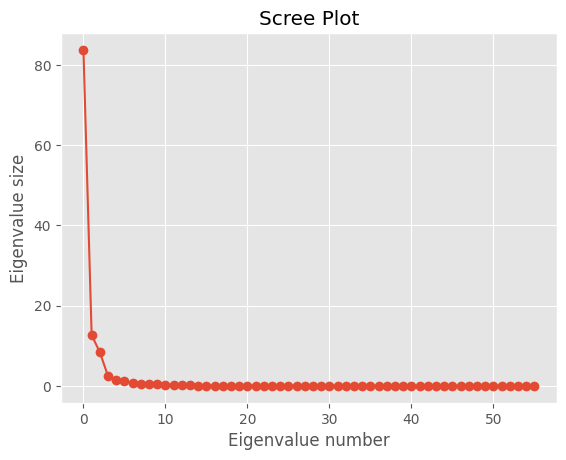

In [8]:
import matplotlib.pyplot as plt
plt.style.use("ggplot") 
plt.plot(pca.explained_variance_, marker='o')
plt.xlabel("Eigenvalue number")
plt.ylabel("Eigenvalue size")
plt.title("Scree Plot")

In [9]:
cumvar = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cumvar >= 0.99) + 1
print(f"Components for 99% variance: {n_components}")

Components for 99% variance: 11


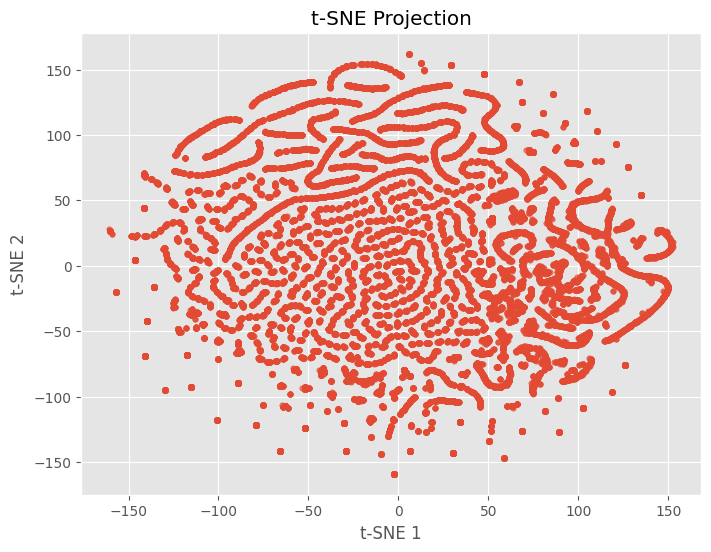

In [10]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import polars as pl
import numpy as np

pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)

rng = np.random.default_rng(42)

sample_size = min(50000, X_pca.shape[0])
idx = rng.choice(X_pca.shape[0], size=sample_size, replace=False)

X_pca_sample = X_pca[idx]
X_scaled_sample = X_scaled[idx]

projection = TSNE(
  n_components=2,
  perplexity=40,
  init="pca",
  learning_rate="auto",
  random_state=42,
).fit_transform(X_pca_sample)

# Plot
plt.figure(figsize=(8, 6))
plt.scatter(
  projection[:, 0],
  projection[:, 1],
  s=15,
  alpha=0.7,
)
plt.title("t-SNE Projection")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

[Link to source for optimal hyperparameters DBSCAN](https://www.datacamp.com/tutorial/dbscan-clustering-algorithm?utm_cid=19589720821&utm_aid=157156374951&utm_campaign=230119_1-ps-other~dsa-tofu~all_2-b2c_3-emea_4-prc_5-na_6-na_7-le_8-pdsh-go_9-nb-e_10-na_11-na&utm_loc=9103947-&utm_mtd=-c&utm_kw=&utm_source=google&utm_medium=paid_search&utm_content=ps-other~emea-en~dsa~tofu~tutorial~machine-learning&gad_source=1&gad_campaignid=19589720821&gbraid=0AAAAADQ9WsFcsoU6viY__K-SLCYqgJGS4&gclid=EAIaIQobChMI9au7_OmSlAMV-7KDBx1TADZ4EAAYASAAEgLCwvD_BwE)

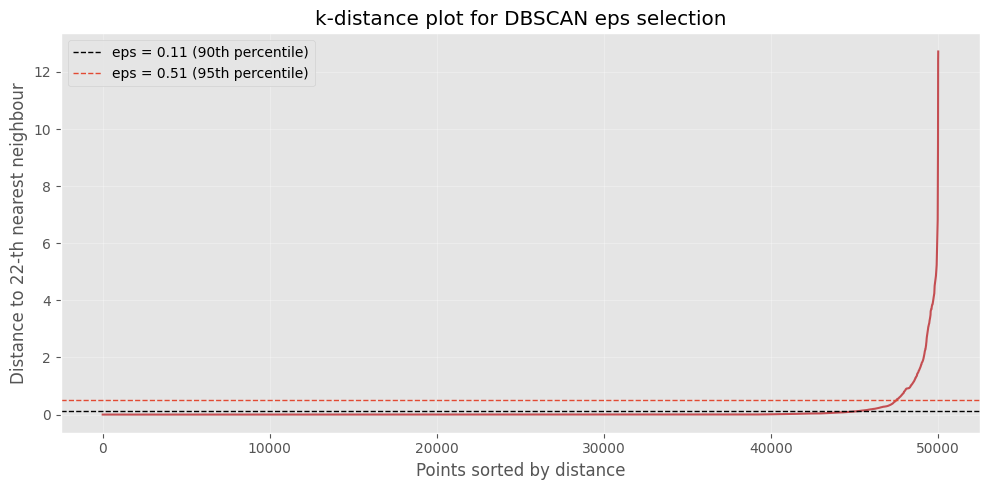

In [11]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt
import os

# k = 2 × n_features (rule of thumb for DBSCAN min_samples)
min_samples = X_pca_sample.shape[1] * 2

nbrs = NearestNeighbors(n_neighbors=min_samples).fit(X_pca_sample)
distances, _ = nbrs.kneighbors(X_pca_sample)
k_distances = np.sort(distances[:, -1])

p90 = np.percentile(k_distances, 90)
p95 = np.percentile(k_distances, 95)

os.makedirs('figures/22_(h)dbscan', exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_distances, color='#c44e52', linewidth=1.5)
ax.axhline(p90, color='#000000', linestyle='--', linewidth=1,label=f'eps = {p90:.2f} (90th percentile)')
ax.axhline(p95, linestyle='--', linewidth=1,label=f'eps = {p95:.2f} (95th percentile)')
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel(f"Distance to {min_samples}-th nearest neighbour")
ax.set_title("k-distance plot for DBSCAN eps selection")
ax.legend(loc='upper left', frameon=True)
ax.grid(alpha=0.3)

plt.savefig('figures/22_(h)dbscan/dbscan_eps_selection.png', dpi=150)
plt.tight_layout()
plt.show()

Min Samples: 22
Clusters found: 68
Amount of Noise: 4385 (8.77%)


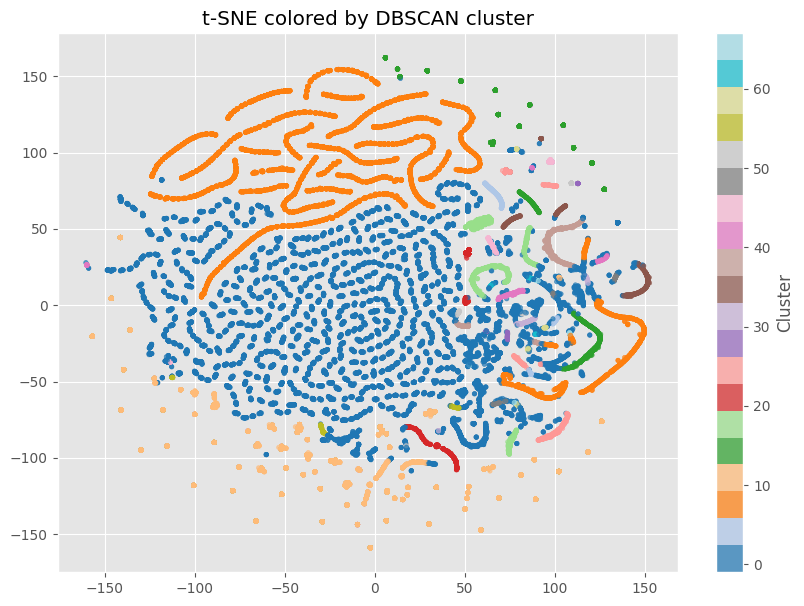

In [12]:
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

eps = np.percentile(k_distances, 90)

dbscan = DBSCAN(eps=eps, min_samples=min_samples)
clusters = dbscan.fit_predict(X_pca_sample)

n_clusters = len(set(clusters)) - (1 if -1 in clusters else 0)
n_noise = list(clusters).count(-1)

print(f"Min Samples: {min_samples}")
print(f"Clusters found: {n_clusters}")
print(f"Amount of Noise: {n_noise} ({ (n_noise/len(clusters))*100 :.2f}%)")

plt.figure(figsize=(10, 7))
plt.scatter(projection[:, 0], projection[:, 1], c=clusters, cmap='tab20', s=10, alpha=0.7)
plt.colorbar(label='Cluster')
plt.title("t-SNE colored by DBSCAN cluster")
plt.savefig('figures/22_(h)dbscan/dbscan_tsn.png', dpi=150)
plt.show()

HDBSCAN better fit for the differences in density regions

### Compare diffrerent strategies

/Users/jesusbeneytogomez-polo/Desktop/thesis/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/jesusbeneytogomez-polo/Desktop/thesis/.venv/lib/python3.13/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(
/Users/jesusbeneytogomez-polo/Desktop/thesis/.venv/lib/python3.13/site-packages/umap/spectral.py:548: UserWarning: Spectral initialisation failed! The eigenvector solver
failed. This is likely due to too small an eigengap. Consider
adding some noise or jitter to your data.

Falling back to random initialisation!
  warn(


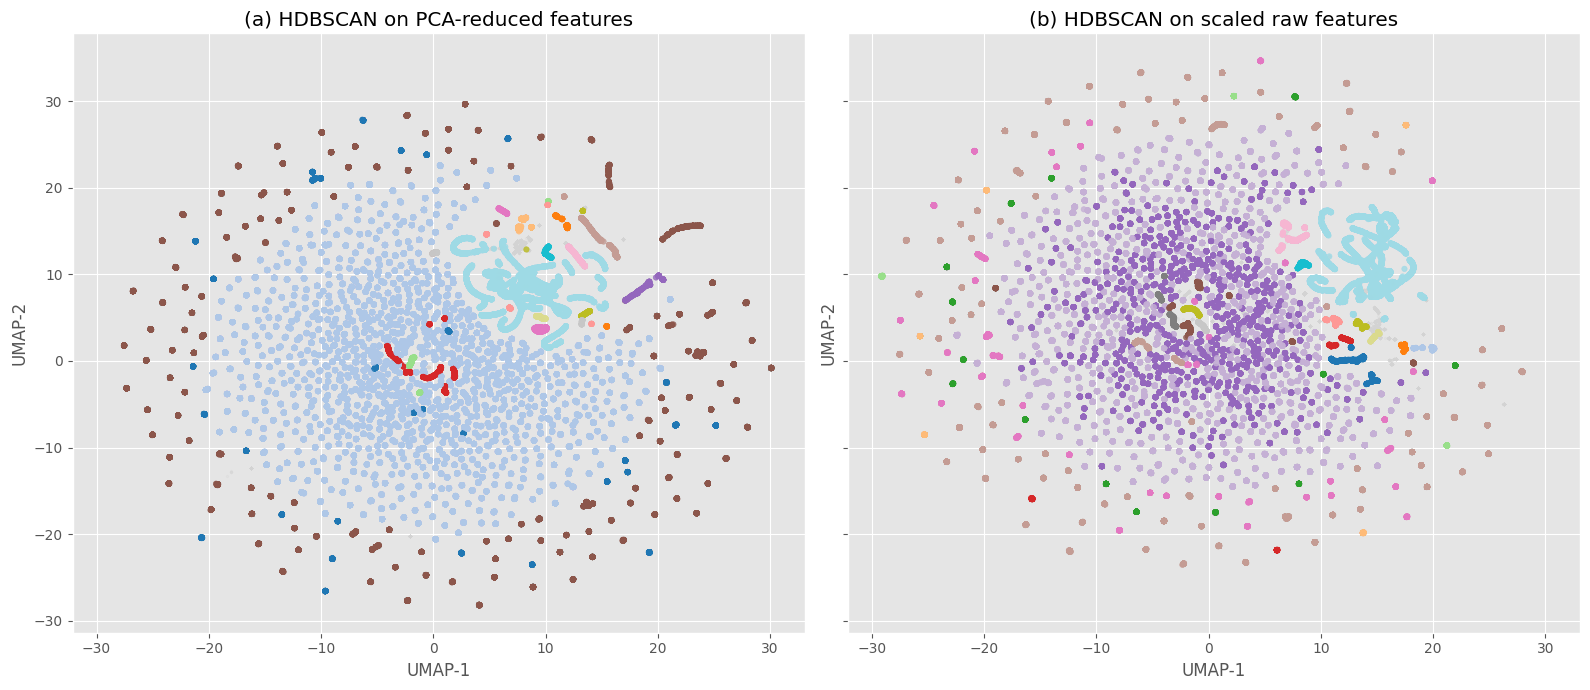

In [13]:
import umap
import hdbscan

clusterer = hdbscan.HDBSCAN(
  min_cluster_size=100,
  min_samples=20,
  cluster_selection_epsilon=1.0,
  cluster_selection_method='leaf'
)
hdb_clusters_pca = clusterer.fit_predict(X_pca_sample)
hdb_clusters_scaled = clusterer.fit_predict(X_scaled_sample)

reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
projection_pca = reducer.fit_transform(X_pca_sample)
projection_scaled = reducer.fit_transform(X_scaled_sample)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

for ax, (clusters, proj, title) in zip(axes, [
  (hdb_clusters_pca, projection_pca, "(a) HDBSCAN on PCA-reduced features"),
  (hdb_clusters_scaled, projection_scaled, "(b) HDBSCAN on scaled raw features"),
]):
  mask = clusters != -1
  ax.scatter(proj[~mask, 0], proj[~mask, 1], c='lightgrey', s=3, alpha=0.2)
  ax.scatter(proj[mask, 0], proj[mask, 1], c=clusters[mask], cmap='tab20', s=15, alpha=0.8)
  ax.set_title(title)
  ax.set_xlabel("UMAP-1"); ax.set_ylabel("UMAP-2")

plt.savefig('figures/22_(h)dbscan/hdbscan_scaled_vs_pca.png', dpi=150)
plt.tight_layout()

### Compare different hyperparameters

In [14]:
import hdbscan
import pandas as pd

results = []
for mcs in [50, 100, 200, 400]:
  for ms in [10, 20, 50]:
    for eps in [0.0, 0.5, 1.0, 1.5]:
      for method in ['eom', 'leaf']:
        labels = hdbscan.HDBSCAN(
          min_cluster_size=mcs,
          min_samples=ms,
          cluster_selection_epsilon=eps,
          cluster_selection_method=method,
        ).fit_predict(X_pca_sample)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_pct = (labels == -1).mean() * 100
        largest = pd.Series(labels[labels != -1]).value_counts().iloc[0] \
          if n_clusters > 0 else 0
        results.append({
          'min_cluster_size': mcs,
          'min_samples': ms,
          'eps': eps,
          'method': method,
          'n_clusters': n_clusters,
          'noise_%': round(noise_pct, 1),
          'largest_cluster': largest,
        })

df_grid = pd.DataFrame(results)
print(df_grid.to_string(index=False))

 min_cluster_size  min_samples  eps method  n_clusters  noise_%  largest_cluster
               50           10  0.0    eom         163      5.0             2190
               50           10  0.0   leaf         407     16.3              373
               50           10  0.5    eom          46      2.1            17531
               50           10  0.5   leaf          46      2.1            17531
               50           10  1.0    eom          30      1.2            26489
               50           10  1.0   leaf          30      1.2            26489
               50           10  1.5    eom          28      1.1            26565
               50           10  1.5   leaf          28      1.1            26565
               50           20  0.0    eom         151      5.7             2190
               50           20  0.0   leaf         377     20.9              439
               50           20  0.5    eom          45      2.7            17531
               50           

In [15]:
import hdbscan

clusterer_100 = hdbscan.HDBSCAN( min_cluster_size=100, min_samples=20, cluster_selection_epsilon=0.5, cluster_selection_method='eom')
hdb_clusters_100 = clusterer_100.fit_predict(X_pca_sample)

clusterer_200 = hdbscan.HDBSCAN( min_cluster_size=200, min_samples=20, cluster_selection_epsilon=0.5, cluster_selection_method='eom')
hdb_clusters_200 = clusterer_200.fit_predict(X_pca_sample)


In [16]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
import numpy as np

def evaluate_multi_seed(X, labels, name, n_seeds=8, sample_size=20000):
  sils, dbs = [], []
  for seed in range(n_seeds):
    rng = np.random.default_rng(seed)
    sample_idx = rng.choice(len(X), min(sample_size, len(X)), replace=False)
    X_sample, labels_sample = X[sample_idx], labels[sample_idx]
    mask = labels_sample != -1
    sils.append(silhouette_score(X_sample[mask], labels_sample[mask]))
    dbs.append(davies_bouldin_score(X_sample[mask], labels_sample[mask]))
  
  sils, dbs = np.array(sils), np.array(dbs)
  n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
  noise_pct = (labels == -1).mean() * 100
  print(f"{name}")
  print(f"Clusters: {n_clusters}")
  print(f"Noise: {noise_pct:.1f}%")
  print(f"Silhouette: {sils.mean():.4f}")
  print(f"Davies-Bouldin: {dbs.mean():.4f}")

evaluate_multi_seed(X_pca_sample, hdb_clusters_200, "mcs=200")
evaluate_multi_seed(X_pca_sample, hdb_clusters_100, "mcs=100")

mcs=200
Clusters: 19
Noise: 5.2%
Silhouette: 0.7485
Davies-Bouldin: 0.4838
mcs=100
Clusters: 28
Noise: 3.9%
Silhouette: 0.7486
Davies-Bouldin: 0.6208


In [17]:
clusterer_150 = hdbscan.HDBSCAN(min_cluster_size=150, min_samples=20,cluster_selection_epsilon=0.5, cluster_selection_method='eom')
hdb_clusters_150 = clusterer_150.fit_predict(X_pca_sample)
evaluate_multi_seed(X_pca_sample, hdb_clusters_150, "mcs=150")


mcs=150
Clusters: 23
Noise: 5.2%
Silhouette: 0.7514
Davies-Bouldin: 0.4808


### BEST RUN min_cluster_size=150, min_samples=20,cluster_selection_epsilon=0.5

/Users/jesusbeneytogomez-polo/Desktop/thesis/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


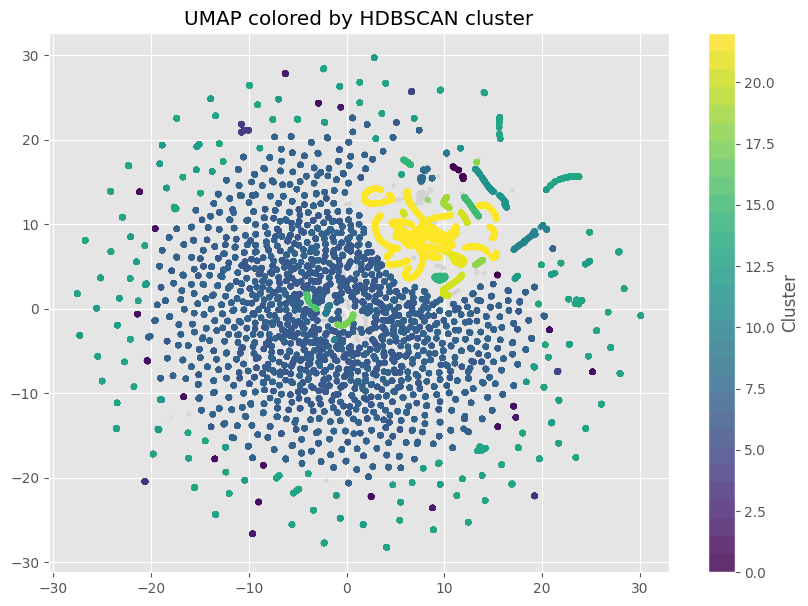

In [18]:
import umap

clusterer = hdbscan.HDBSCAN(
  min_cluster_size=150,
  min_samples=20,
  cluster_selection_epsilon=0.5,
  cluster_selection_method='eom'
)
hdb_clusters = clusterer.fit_predict(X_pca_sample)

reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=42)
projection = reducer.fit_transform(X_pca_sample)

cmap_30 = plt.get_cmap('viridis').resampled(30)

mask = hdb_clusters != -1
plt.figure(figsize=(10, 7))
plt.scatter(projection[~mask, 0], projection[~mask, 1], c='lightgrey', s=3, alpha=0.2, label='noise')
plt.scatter(projection[mask, 0], projection[mask, 1], c=hdb_clusters[mask], cmap=cmap_30, s=15, alpha=0.8)
plt.colorbar(label='Cluster')
plt.title("UMAP colored by HDBSCAN cluster")
plt.savefig('figures/22_(h)dbscan/hdbscan_umap.png', dpi=150)
plt.show()

#### Overview (Check cluster_representatives/ better)

In [19]:
import ast

df_full = pd.read_csv("results/sorted_enriched_port_22.csv", low_memory=False)
df_full_sample = df_full.iloc[idx].copy()
df_full_sample["cluster"] = hdb_clusters

stat_cols = [
  'bidirectional_packets', 'bidirectional_bytes', 'bidirectional_duration_ms',
  'bidirectional_syn_packets', 'bidirectional_rst_packets', 'bidirectional_fin_packets'
]

for c in sorted(df_full_sample["cluster"].unique()):
  subset = df_full_sample[df_full_sample["cluster"] == c]
  stats = subset[stat_cols].mean().round(1)

  # Did the SSH handshake complete
  handshake_rate = subset['clients'].notna().mean()

  # Authentication outcome
  auth = subset['auth_success'].dropna().value_counts().to_dict()

  # Client banner 
  clients = []
  for v in subset['clients'].dropna():
    try: clients.extend(ast.literal_eval(v))
    except: pass
  clients = pd.Series(clients).value_counts().to_dict() if clients else {}

  print(f"\nCluster {c} ({len(subset)} flows)")
  print(f"pkts={stats['bidirectional_packets']} "
    f"bytes={stats['bidirectional_bytes']} "
    f"dur={stats['bidirectional_duration_ms']}ms "
    f"syn={stats['bidirectional_syn_packets']} "
    f"rst={stats['bidirectional_rst_packets']} "
    f"fin={stats['bidirectional_fin_packets']} "
    f"handshake_rate: {handshake_rate} ")
  if auth: print(f"auth_success: {auth} ")
  if clients: print(f"clients: {clients}")


Cluster -1 (2585 flows)
pkts=101.3 bytes=80859.8 dur=13058.4ms syn=3.0 rst=0.4 fin=1.1 handshake_rate: 0.5261121856866537 
auth_success: {'unknown': 1080, 'success': 267, 'failed': 13} 
clients: {'SSH-2.0-Go': 472, 'SSH-2.0-libssh_0.11.1': 238, 'SSH-2.0-PUTTY': 122, 'SSH-2.0-AsyncSSH_2.1.0': 54, 'SSH-2.0-ZGrab ZGrab SSH Survey': 24, 'SSH-2.0-OpenSSH_8.4p1 Debian-5+deb11u3': 23, 'SSH-2.0-OPENSSH_7.9': 13, 'SSH-2.0-libssh_0.9.6': 12, 'SSH-2.0-OpenSSH-keyscan': 12, 'SSH-2.0-libssh-0.1': 11, 'SSH-2.0-libssh2_1.11.0': 10, 'SSH-2.0-libssh_0.7.4': 10, 'SSH-2.0-PuTTY_Release_0.80': 7, 'SSH-2.0-libssh_0.10.5': 6, 'SSH-2.0-paramiko_3.4.0': 6, 'SSH-2.0-perlssh': 6, 'SSH-2.0-OpenSSH_9.9': 5, 'SSH-2.0-OpenSSH_8.9p19': 3, 'SSH-2.0-libssh2_1.9.0': 3, 'SSH-2.0-Nmap-SSH2-Hostkey': 3, 'SSH-2.0-ROSSSH': 3, 'SSH-2.0-OpenSSH_10.0': 2, 'SSH-2.0-russh_0.51.1': 2, 'SSH-2.0-zgrab2 opt-out available at http://195.37.190.89': 2, 'SSH-2.0-OpenSSH': 2, 'SSH-2.0-libssh2_1.11.1': 2, 'SSH-2.0-makiko': 1, 'SSH-2.0-Op

### Overiview of how each feature impacts each cluster

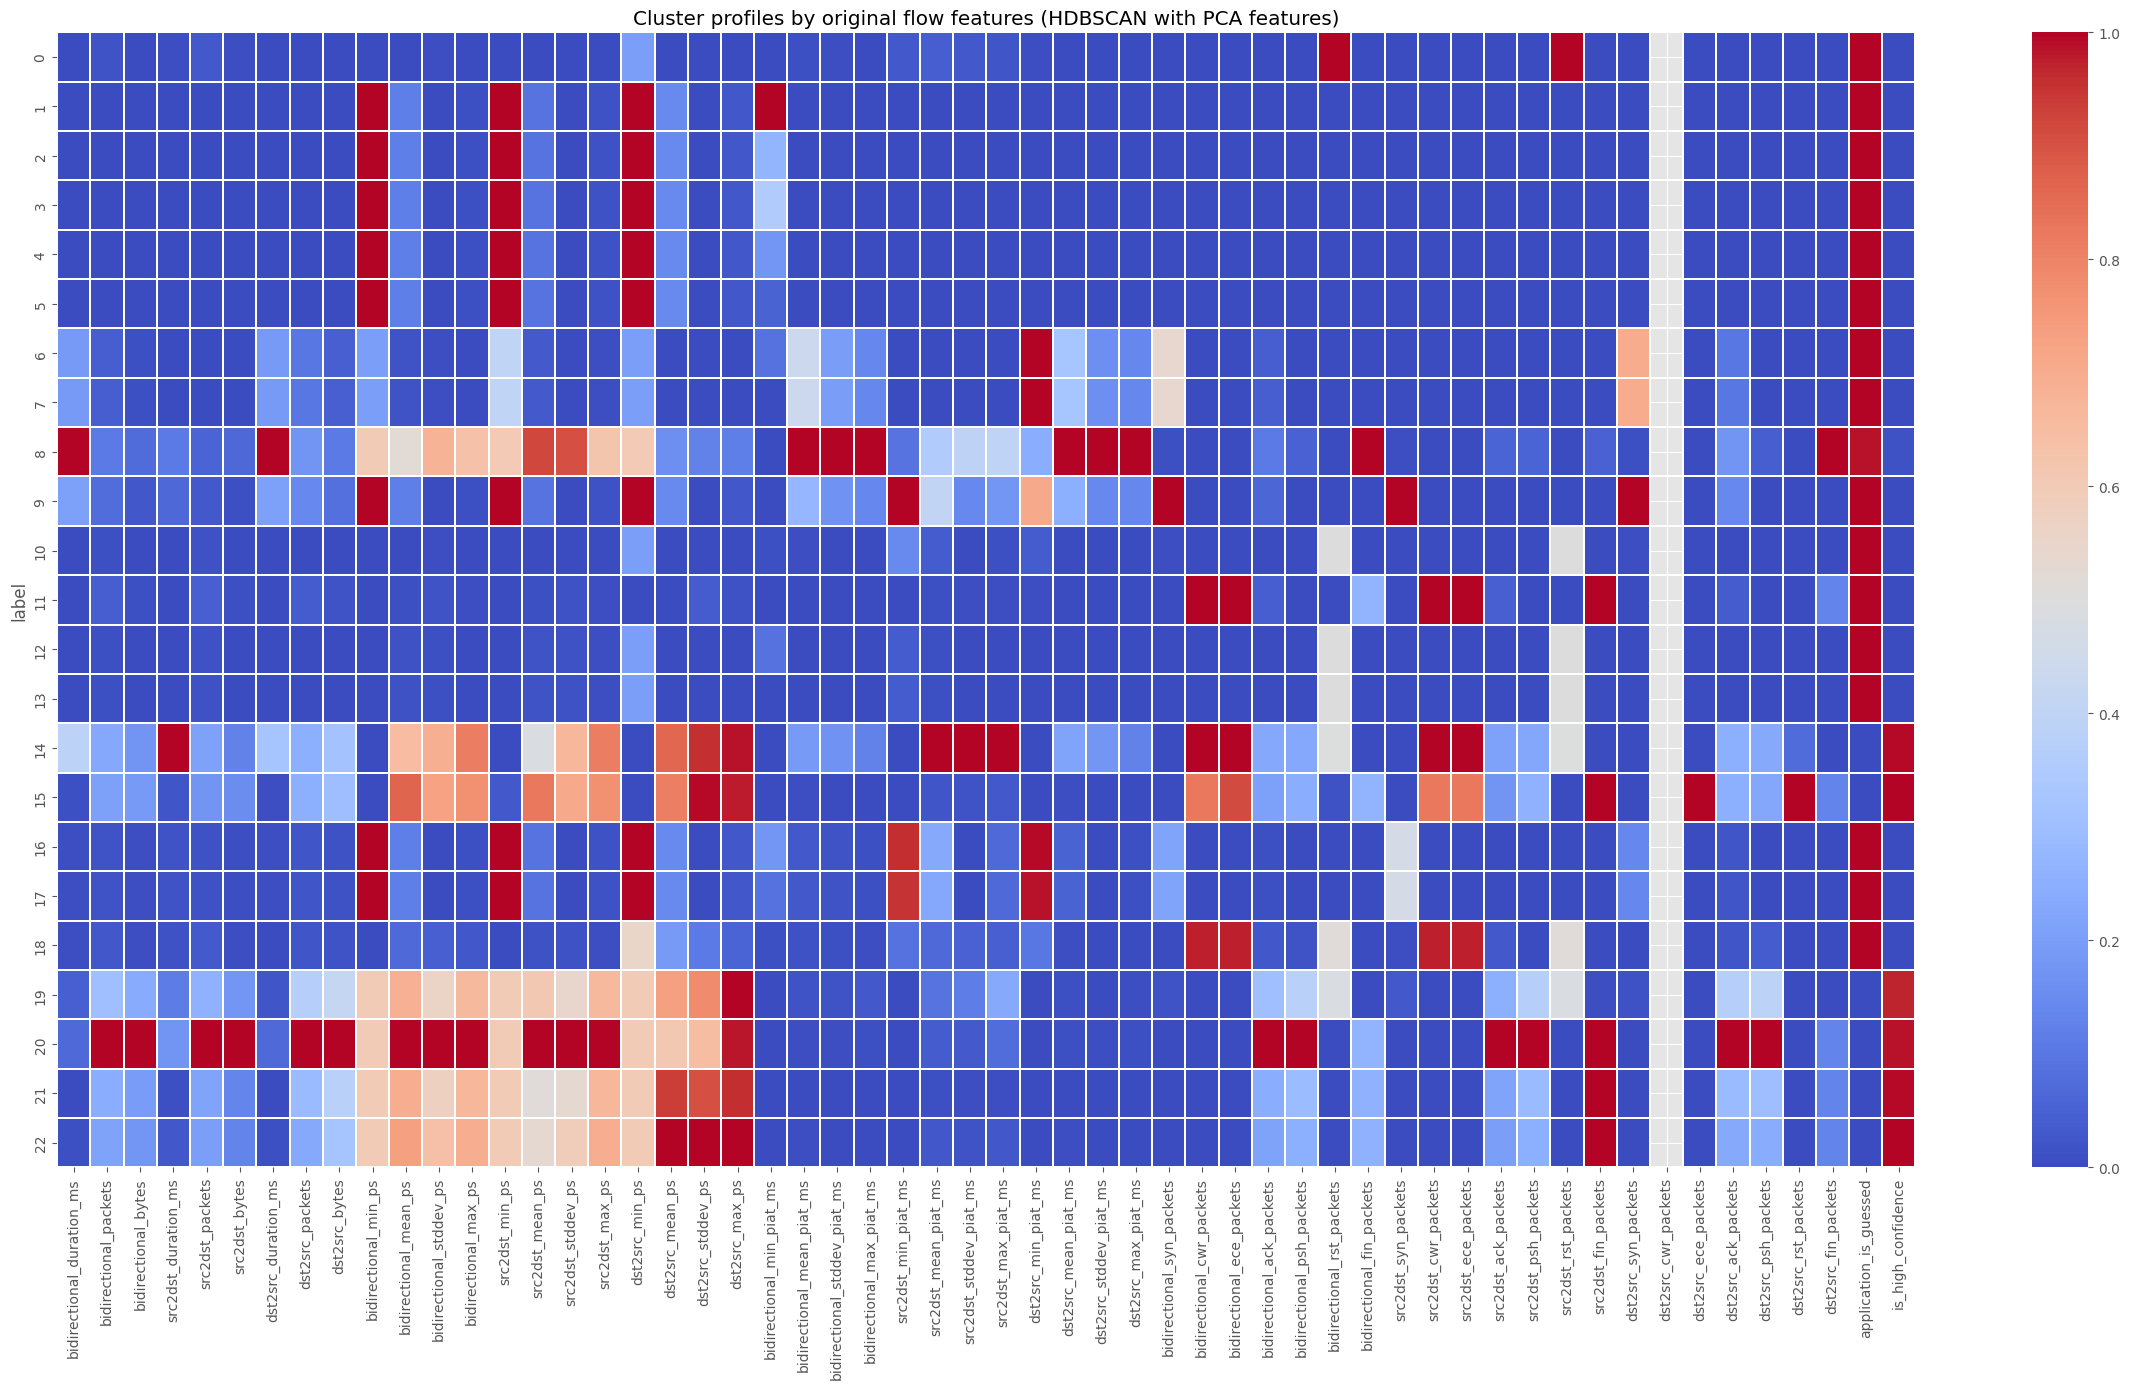

In [20]:
import seaborn as sns

X_sample = X[idx]
df_original = pd.DataFrame(X_sample, columns=original_feature_names)
df_original["cluster"] = hdb_clusters

# Exclude noise for heatmap
df_clean = df_original[df_original["cluster"] != -1].copy()
df_clean["label"] = df_clean["cluster"]

cluster_means = df_clean.groupby("label")[original_feature_names].mean()
normalized = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min())

plt.figure(figsize=(24, 14))
sns.heatmap(normalized, annot=False, cmap='coolwarm', linewidths=0.3)
plt.title('Cluster profiles by original flow features (HDBSCAN with PCA features)')
plt.tight_layout()
plt.savefig('figures/22_(h)dbscan/hdbscan_feature_map.png', dpi=150)
plt.show()

In [21]:
# Print top distinguishing features per cluster

cluster_means = df_original.groupby('cluster').mean()

feature_variance = cluster_means.var().sort_values(ascending=False)

# Normalize before taking variance so scale doesn't dominate
normalized_means = (cluster_means - cluster_means.min()) / (cluster_means.max() - cluster_means.min())
feature_variance_normalized = normalized_means.var().sort_values(ascending=False)

top_features = feature_variance_normalized.index.tolist()

for c in sorted(df_original["cluster"].unique()):
  if c == -1:
    continue
  subset = df_original[df_original["cluster"] == c]
  print(f"\nCluster {c} ({len(subset)} flows)")
  print(subset[top_features].mean().sort_values(ascending=False).head(5).to_string())


Cluster 0 (166 flows)
src2dst_duration_ms          351.331325
bidirectional_duration_ms    351.331325
src2dst_max_piat_ms          321.397590
bidirectional_max_piat_ms    319.765060
bidirectional_bytes          223.192771

Cluster 1 (967 flows)
bidirectional_bytes     148.0
dst2src_min_ps           74.0
dst2src_mean_ps          74.0
src2dst_max_ps           74.0
bidirectional_max_ps     74.0

Cluster 2 (295 flows)
bidirectional_bytes     148.0
dst2src_min_ps           74.0
dst2src_mean_ps          74.0
src2dst_max_ps           74.0
bidirectional_max_ps     74.0

Cluster 3 (224 flows)
bidirectional_bytes     148.0
dst2src_min_ps           74.0
dst2src_mean_ps          74.0
src2dst_max_ps           74.0
bidirectional_max_ps     74.0

Cluster 4 (209 flows)
bidirectional_bytes     148.0
dst2src_min_ps           74.0
dst2src_mean_ps          74.0
src2dst_max_ps           74.0
bidirectional_max_ps     74.0

Cluster 5 (175 flows)
bidirectional_bytes      148.0
bidirectional_mean_ps     74.0


In [22]:
# For each cluster, show what makes it DIFFERENT from the rest
baseline = df_original[df_original["cluster"] != -1].mean()

for c in sorted(df_original["cluster"].unique()):
  if c == -1:
    continue
  subset = df_original[df_original["cluster"] == c]
  # Ratio: distinctive high, low = distinctive low
  ratio = (subset.mean() / (baseline + 1e-9)).sort_values(ascending=False)
  
  print(f"\nCluster {c} ({len(subset)} flows)")
  print("HIGH:", ratio.head(4).index.tolist())
  print("LOW:", ratio.tail(4).index.tolist())


Cluster 0 (166 flows)
HIGH: ['src2dst_rst_packets', 'bidirectional_rst_packets', 'src2dst_stddev_piat_ms', 'src2dst_mean_piat_ms']
LOW: ['dst2src_stddev_piat_ms', 'bidirectional_fin_packets', 'bidirectional_psh_packets', 'cluster']

Cluster 1 (967 flows)
HIGH: ['bidirectional_min_piat_ms', 'bidirectional_min_ps', 'dst2src_min_ps', 'src2dst_min_ps']
LOW: ['dst2src_mean_piat_ms', 'dst2src_min_piat_ms', 'src2dst_min_piat_ms', 'src2dst_max_piat_ms']

Cluster 2 (295 flows)
HIGH: ['bidirectional_min_piat_ms', 'bidirectional_min_ps', 'dst2src_min_ps', 'src2dst_min_ps']
LOW: ['dst2src_mean_piat_ms', 'dst2src_min_piat_ms', 'src2dst_min_piat_ms', 'src2dst_max_piat_ms']

Cluster 3 (224 flows)
HIGH: ['bidirectional_min_piat_ms', 'bidirectional_min_ps', 'dst2src_min_ps', 'src2dst_min_ps']
LOW: ['dst2src_mean_piat_ms', 'dst2src_min_piat_ms', 'src2dst_min_piat_ms', 'src2dst_max_piat_ms']

Cluster 4 (209 flows)
HIGH: ['bidirectional_min_piat_ms', 'bidirectional_min_ps', 'dst2src_min_ps', 'src2dst_min

In [25]:
import numpy as np
import os

df_full_sample["cluster_probability"] = clusterer.probabilities_

os.makedirs("clusters/clusters_22_hdbscan", exist_ok=True)

cluster_sizes = df_full_sample["cluster"].value_counts().to_dict()

for cluster_id in sorted(df_full_sample["cluster"].unique()):
  if cluster_id == -1:
    continue
  subset_idx = df_full_sample.index[df_full_sample["cluster"] == cluster_id].to_numpy()
  # Most representative by HDBSCAN probability
  representative_idx = (df_full_sample.loc[subset_idx].sort_values("cluster_probability", ascending=False).head(50).index)
  # Furthest away / most anomalous by lowest HDBSCAN probability
  anomalous_idx = (df_full_sample.loc[subset_idx].sort_values("cluster_probability", ascending=True).head(50).index)
  
  df_full_sample.loc[representative_idx].to_csv(f"clusters/clusters_22_hdbscan/{cluster_id:02d}_representative.csv",index=False)
  df_full_sample.loc[anomalous_idx].to_csv(f"clusters/clusters_22_hdbscan/{cluster_id:02d}_anomalous.csv",index=False)
  print(f"Saved cluster {cluster_id} ({cluster_sizes[cluster_id]} flows)")

Saved cluster 0 (166 flows)
Saved cluster 1 (967 flows)
Saved cluster 2 (295 flows)
Saved cluster 3 (224 flows)
Saved cluster 4 (209 flows)
Saved cluster 5 (175 flows)
Saved cluster 6 (8958 flows)
Saved cluster 7 (17531 flows)
Saved cluster 8 (216 flows)
Saved cluster 9 (352 flows)
Saved cluster 10 (310 flows)
Saved cluster 11 (436 flows)
Saved cluster 12 (2598 flows)
Saved cluster 13 (7409 flows)
Saved cluster 14 (470 flows)
Saved cluster 15 (302 flows)
Saved cluster 16 (181 flows)
Saved cluster 17 (201 flows)
Saved cluster 18 (168 flows)
Saved cluster 19 (218 flows)
Saved cluster 20 (546 flows)
Saved cluster 21 (282 flows)
Saved cluster 22 (5201 flows)


### Family based in the inspected clusters

latest